# A/B-тест новой формы оплаты ЖКХ

- Автор: Васильев Арсений
- Дата: 07.11.2026

## Цель и задачи

Команда платежей запустила A/B-тест новой формы оплаты ЖКХ. В новой форме упрощено заполнение реквизитов, то есть клиенту нужно вводить меньше данных. Тест шел 30 дней (с 1 по 30 апреля 2024). Клиентов разделили на две группы:
- группа A - старая форма оплаты;
- группа B - новая упрощенная форма.

Оплата проходит в 4 шага:
1. Открыл форму;
2. Ввел реквизиты;
3. Подтвердил платеж;
4. Успешная оплата.

**Ключевая метрика** - конверсия из шага 1 в шаг 4.

**Гипотеза:** новая форма увеличит долю успешных оплат ЖКХ.

**Цель проекта:** понять, стоит ли запускать новую форму на всех пользователей.

**Задачи:**
1. Загрузить данные и проверить их качество: найти пропуски и аномальные значения, очистить данные;
2. Проверить корректное разделение на группы;
3. Построить воронку оплаты и сравнить группы;
4. Статистически проверить гипотезу;
5. Визуализировать результаты;
6. Сформулировать рекомендацию для продуктовой команды.

## Описание данных
Исходный excel-файл формата .xlsx с двумя листами был разделен на два отдельных файла формата .csv для удобства.

Файл `users.csv` (1504 строки) - клиенты, участвовавшие в тесте:
- `user_id` - id клиента;
- `group` - группа (A или B);
- `age` - возраст;
- `city` - город (Москва, СПб, Регион);
- `device_type` - устройство (ios или android).

Файл `payments.csv` (2661 строка) - попытки оплаты ЖКХ за время теста:
- `payment_id` - id попытки;
- `user_id` - id клиента;
- `group` - группа;
- `step1_opened`, `step2_entered`, `step3_confirmed`, `step4_success` - время, когда клиент дошел до шага (если пусто, до этого шага он не дошёл).

У одного клиента может быть несколько попыток оплаты. Разделение на группы делали по клиентам.

## Содержание
1. [Загрузка и первичный осмотр](#Загрузка-и-первичный-осмотр)
2. [Проверка качества данных](#Проверка-качества-данных)
3. [Проверка корректности сплита](#Проверка-корректности-сплита)
4. [EDA и воронка](#EDA-и-воронка)
5. [Статистический тест](#Статистический-тест)
6. [Визуализация](#Визуализация)
7. [Рекомендация](#Рекомендация)

## Загрузка и первичный осмотр

Загрузим все необходимые библиотеки.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest

Загрузим данные: таблицу клиентов (users.csv) и таблицу платежей (payments.csv).

In [2]:
df_users = pd.read_csv('users.csv', sep=';', encoding='cp1251')
df_payments = pd.read_csv('payments.csv', sep=';', encoding='cp1251')

Посмотрим на таблицу клиентов: первые строки, типы данных и основные статистики.

In [3]:
display(df_users.head())
display(df_users.info())
display(df_users.describe())

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB


None

,user_id,age
count,1504.000000,1504.000000
mean,1769.787234,32.745346
std,571.592080,8.410915
min,1001.000000,-5.000000
25%,1376.750000,27.000000
50%,1752.500000,33.000000
75%,2128.250000,38.000000
max,9004.000000,150.000000


- в `group` и `city` есть по одному пропуску (всего 1504 строки, а заполнено 1503);
- возраст `age` от -5 до 150;
- максимальный `user_id` равен 9004, хотя у большинства клиентов id около 1000-2500.

Теперь посмотрим на таблицу платежей.

In [4]:
display(df_payments.head())
display(df_payments.info())
display(df_payments.describe())

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaN,NaN
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaN,NaN
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaN,NaN
3,5004,1004.0,A,2024-04-09 16:02:00,NaN,NaN,NaN
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   payment_id       2661 non-null   int64  
 1   user_id          2660 non-null   float64
 2   group            2661 non-null   object 
 3   step1_opened     2661 non-null   object 
 4   step2_entered    2256 non-null   object 
 5   step3_confirmed  1719 non-null   object 
 6   step4_success    1522 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 145.6+ KB


None

,payment_id,user_id
count,2661.000000,2660.000000
mean,6433.978579,1760.884211
std,3203.640974,456.521127
min,5001.000000,1001.000000
25%,5666.000000,1388.000000
50%,6331.000000,1762.500000
75%,6996.000000,2135.250000
max,99003.000000,9004.000000


- в `user_id` один пропуск - платеж без клиента;
- почти все `payment_id` в диапазоне 5001-7658, а максимум 99003;
- много пропусков в `step2_entered`, `step3_confirmed` и `step4_success` - клиент не дошел до этих шагов;
- столбцы с датами хранятся как текст (`object`), их нужно перевести в формат даты.

Переведем столбцы с датами в формат datetime.

In [5]:
date_cols = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
for col in date_cols:
    df_payments[col] = pd.to_datetime(df_payments[col])

df_payments.dtypes

payment_id                  int64
user_id                   float64
group                      object
step1_opened       datetime64[ns]
step2_entered      datetime64[ns]
step3_confirmed    datetime64[ns]
step4_success      datetime64[ns]
dtype: object

## Проверка качества данных

Запомним, сколько строк было в таблицах до очистки.

In [6]:
users_shape = df_users.shape[0]
payments_shape = df_payments.shape[0]

Выведем проблемные записи, которые были найдены выше: пропуски, странный возраст и странные номера платежей.

In [7]:
print('Клиенты без группы или без города:')
print(df_users[df_users['group'].isna() | df_users['city'].isna()])

print('Клиенты с невозможным возрастом:')
print(df_users[(df_users['age'] < 14) | (df_users['age'] > 100)])

print('Платежи без клиента:')
print(df_payments[df_payments['user_id'].isna()])

print('Платежи с большим номером:')
print(df_payments[df_payments['payment_id'] > 90000])

Клиенты без группы или без города:
      user_id group  age    city device_type
1500     9001   NaN   25  Москва         ios
1503     9004     A   30     NaN     android
Клиенты с невозможным возрастом:
      user_id group  age    city device_type
1501     9002     A   -5     СПб     android
1502     9003     B  150  Регион         ios
Платежи без клиента:
      payment_id  user_id group        step1_opened step2_entered  \
2660       99003      NaN     A 2024-04-12 09:15:00           NaT   

     step3_confirmed step4_success  
2660             NaT           NaT  
Платежи с большим номером:
      payment_id  user_id group        step1_opened       step2_entered  \
2658       99001   1005.0     A 2024-04-05 10:30:00 2024-04-05 10:33:00   
2659       99002   1010.0     B 2024-04-08 14:20:00 2024-04-08 14:23:00   
2660       99003      NaN     A 2024-04-12 09:15:00                 NaT   

         step3_confirmed       step4_success  
2658 2024-04-05 10:38:00 2024-04-05 10:39:00  
2659 2

- клиентов 9001 (нет группы) и 9004 (нет города) можно удалить, тк без группы или города клиента нельзя корректно учесть в анализе;
- клиентов 9002 (возраст -5) и 9003 (возраст 150) удаляем, данные ошибочны;
- платеж без клиента (payment_id 99003) удаляем, не понятно кто выполнял этот платеж;
- платежи 99001–99003 - номера сильно выбиваются из остальных, возможно это тестовые или служебные записи. Удалим все три;
- платежи удаленных клиентов тоже удалим, иначе у них не будет данных о клиенте.

Очистим данные.

In [8]:
# клиенты: убираем пропуски и невозможный возраст
df_users = df_users.dropna()
df_users = df_users[(df_users['age'] >= 14) & (df_users['age'] <= 100)].copy()

# платежи: убираем платежи без клиента
df_payments = df_payments.dropna(subset=['user_id'])
# убираем платежи 99001-99003
df_payments = df_payments[df_payments['payment_id'] < 90000]
# убираем платежи клиентов, которых удалили выше
df_payments = df_payments[df_payments['user_id'].isin(df_users['user_id'])].copy()

# в user_id был тип float из-за пропуска, возвращаем int
df_payments['user_id'] = df_payments['user_id'].astype(int)

Посмотрим, сколько строк осталось.

In [9]:
print('Клиентов:', users_shape, '->', len(df_users))
print('Платежей:', payments_shape, '->', len(df_payments))

Клиентов: 1504 -> 1500
Платежей: 2661 -> 2657


Всего после очистки было удалено 4 клиента и 4 платежа. Это явно меньше 1% всех данных, на результат анализа не повлияет.

## Проверка корректности сплита

Для корректного проведения статистического теста необходимо убедиться в том, что клиентов разбили на группы случайным образом - группы должны быть примерно одинаковыми по размеру и составу (города, устройства, возраст). Тогда разницу в конверсии можно будет связать именно с новой формой.

Сначала сравним размеры групп.

In [10]:
print(df_users['group'].value_counts())

group
A    750
B    750
Name: count, dtype: int64


Теперь сравним состав групп. Для каждой группы посмотрим доли клиентов по городам, по устройствам и средний возраст.

In [11]:
# доли клиентов по городам внутри каждой группы
print(df_users.groupby('group')['city'].value_counts(normalize=True).round(2))

# доли клиентов по устройствам внутри каждой группы
print(df_users.groupby('group')['device_type'].value_counts(normalize=True).round(2))

# средний возраст в каждой группе
print(df_users.groupby('group')['age'].mean().round(1))

group  city  
A      Москва    0.38
       Регион    0.36
       СПб       0.26
B      Москва    0.41
       Регион    0.33
       СПб       0.27
Name: proportion, dtype: float64
group  device_type
A      android        0.54
       ios            0.46
B      ios            0.51
       android        0.49
Name: proportion, dtype: float64
group
A    32.7
B    32.7
Name: age, dtype: float64


Проверим, что ни один клиент не попал в обе группы сразу.

In [12]:
groups_per_user = df_payments.groupby('user_id')['group'].nunique()
print('Клиентов в обеих группах:', (groups_per_user > 1).sum())

Клиентов в обеих группах: 0


**Вывод по сплиту:**
- размеры групп одинаковые (по 750 клиентов);
- доли по городам, по устройствам и средний возраст почти совпадают;
- клиентов, попавших сразу в обе группы, нет.

Сплит можно считать корректным.

## EDA и воронка

Посчитаем воронку: сколько попыток оплаты дошло до каждого шага в группе A и в группе B.

In [13]:
funnel = pd.DataFrame({
    'Шаг 1': df_payments.groupby('group')['step1_opened'].count(),
    'Шаг 2': df_payments.groupby('group')['step2_entered'].count(),
    'Шаг 3': df_payments.groupby('group')['step3_confirmed'].count(),
    'Шаг 4': df_payments.groupby('group')['step4_success'].count(),
})
print(funnel)

       Шаг 1  Шаг 2  Шаг 3  Шаг 4
group                            
A       1306   1059    756    649
B       1351   1194    960    870


Также сравним доли. Посчитаем, какой процент попыток (от тех, кто открыл форму) дошел до каждого шага. На шаге 4 получится ключевая метрика - конверсия в успешную оплату.

In [14]:
funnel_share = pd.DataFrame({
    'Шаг 1': funnel['Шаг 1'] / funnel['Шаг 1'] * 100,
    'Шаг 2': funnel['Шаг 2'] / funnel['Шаг 1'] * 100,
    'Шаг 3': funnel['Шаг 3'] / funnel['Шаг 1'] * 100,
    'Шаг 4': funnel['Шаг 4'] / funnel['Шаг 1'] * 100,
}).round(1)
print(funnel_share)

       Шаг 1  Шаг 2  Шаг 3  Шаг 4
group                            
A      100.0   81.1   57.9   49.7
B      100.0   88.4   71.1   64.4


- в группе B до успешной оплаты доходит больше попыток: 64,4% против 49,7% в группе A;
- в группе B до каждого шага доходит больше попыток.

## Статистический тест

Пусть pA - конверсия в успешную оплату в группе A (старая форма), pB - в группе B (новая форма).

Сформулируем гипотезы:
- **H0 (нулевая гипотеза):** pB = pA. Новая форма не влияет на долю успешных оплат.
- **H1 (альтернативная гипотеза):** pB > pA. Новая форма увеличивает долю успешных оплат.

Уровень значимости оставляем стандартным: alpha = 0.05 (в 5% случаев готовы ошибиться и признать форму лучшей, хотя на самом деле разницы нет).

Мы сравниваем две доли: долю успешных оплат в группе A и в группе B. Для такого сравнения подходит z-тест двух пропорций.

Условия z-теста:
- Независимые группы: A и B состоят из разных клиентов, пересечений нет;
- Бинарный исход: оплата либо успешна, либо нет;
- Достаточно большие выборки: в каждой группе должно быть не меньше 10 успехов и 10 неуспехов;
- Случайное разбиение на группы.

In [15]:
alpha = 0.05

ok_a = funnel.loc['A', 'Шаг 4']
all_a = funnel.loc['A', 'Шаг 1']
ok_b = funnel.loc['B', 'Шаг 4']
all_b = funnel.loc['B', 'Шаг 1']

z_stat, p_value = proportions_ztest(
    count=[ok_b, ok_a],
    nobs=[all_b, all_a],
    alternative='larger',
)

print('Конверсия A:', round(ok_a / all_a * 100, 1), '%')
print('Конверсия B:', round(ok_b / all_b * 100, 1), '%')
print('p-value:', p_value)

if p_value < alpha:
    print('p-value < alpha: отвергаем нулевую гипотезу. Новая форма статистически значимо увеличила конверсию.')
else:
    print('p-value >= alpha: нет оснований отвергнуть нулевую гипотезу. Значимого различия между формами нет.')

Конверсия A: 49.7 %
Конверсия B: 64.4 %
p-value: 9.525505826301556e-15
p-value < alpha: отвергаем нулевую гипотезу. Новая форма статистически значимо увеличила конверсию.


**Результат:** p-value намного меньше 0.05, значит, мы отвергаем нулевую гипотезу: разница в конверсии между группами не случайна, новая форма действительно увеличила долю успешных оплат.

## Визуализация

Покажем, какая доля попыток доходит до каждого шага в группах A и B.

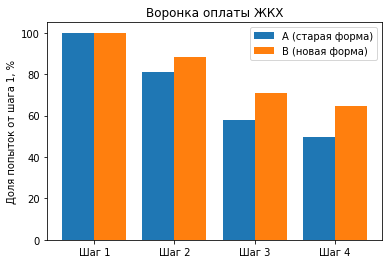

In [16]:
steps = ['Шаг 1', 'Шаг 2', 'Шаг 3', 'Шаг 4']

plt.bar(steps, funnel_share.loc['A'], width=-0.4, align='edge', label='A (старая форма)')
plt.bar(steps, funnel_share.loc['B'], width=0.4, align='edge', label='B (новая форма)')
plt.title('Воронка оплаты ЖКХ')
plt.ylabel('Доля попыток от шага 1, %')
plt.legend()
plt.show()

## Рекомендация

- Конверсия из шага 1 в шаг 4 в группе A (старая форма) равна 49,7%, в группе B (новая форма) - 64,4%. Рост составил 14,7 п.п.
- z-тест для двух пропорций дал p-value сильно меньше alpha = 0.05. Мы отвергаем нулевую гипотезу: разница не случайна.
- Новая форма улучшила переход на каждом шаге воронки.

**Запускать новую форму оплаты на всех пользователей.** Она статистически значимо увеличивает долю успешных оплат.

Ограничения:
- Стоит проверить количество обращений в поддержку после внедрения новой формы оплаты;
- Наблюдать за конверсией после внедрения новой формы.